# Hospital Patient Care Analytics Pipeline

**Author:** Paramkusam Saketha Sreevatsa  
**Course:** Data Engineering Fundamentals  
**Case study:** Multi-specialty hospital patient care analytics

This notebook implements a synthetic end-to-end flow covering patient data integration, doctor working hours, availability-based normal appointments, emergency priority handling and operational analytics. It uses coded identifiers and contains no real patient data. Emergency and risk outputs support staff review only and never replace a doctor's decision.

## tl;dr

The supplied synthetic dataset contains **1,000 raw encounter rows**. Cleaning removes **12 ingestion duplicates**, leaving **988 unique encounters** across **506 coded patients**. All **843 normal appointments** are assigned within the doctor's recorded working hours. The emergency queue contains **145 encounters**, including **9 cases** that require further doctor matching or transfer. Completed encounters average **31.9 minutes of waiting time** and **23.7 minutes of appointment delay**.

## 1. Context & Methods

### CBIM Problem Canvas

**Situation:** A multi-specialty hospital collects information from registration, appointment scheduling, laboratory systems, wearable devices, doctor rosters and consultation records.

**Complication:** These systems use different formats and update speeds. Normal appointments must respect doctor working hours, while emergency cases need rapid identification, an appropriate available or on-call doctor and a visible escalation path when no immediate match exists.

**Question:** How can the hospital integrate and process these records to schedule normal appointments correctly, prioritise emergencies, reduce waiting times and improve operational visibility without replacing clinical judgement?

**Single Source of Truth:** A curated encounter table joined through coded `patient_id`, `encounter_id` and `doctor_id`, supported by a consistent doctor schedule and documented transformation rules.

**Success Definition:** Normal appointments are scheduled inside the assigned doctor's working hours, emergency cases are placed in a priority review queue, unmatched emergencies are escalated, and the pipeline produces trusted waiting-time, delay and doctor-workload measures.

**Primary Stakeholder:** The Hospital Operations Manager, supported by the clinical care team, appointment staff and hospital data team.

### End-to-End Flow

1. Registration, appointment, laboratory, wearable, doctor-roster and consultation data enter the raw layer.
2. The pipeline validates identifiers, timestamps, categories and duplicate encounter records.
3. Normal appointment requests are checked against the assigned doctor's working hours.
4. Emergency encounters receive a source-provided triage level and priority queue position.
5. The system records whether a suitable working or on-call doctor was matched. Cases without an immediate match move to an escalation list.
6. Clean records feed encounter, patient-risk, emergency-review and doctor-workload outputs.
7. Notebook dashboard charts report waiting time, appointment delay, emergency mix and doctor workload.

The emergency workflow highlights and routes cases for authorised clinical review. It does not diagnose the patient or make the doctor's decision.

## 2. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

DATASET_PATH = Path("PARAMKUSAM_SAKETHA_SREEVATSA_Hospital_Patient_Care_Dataset.csv")
OUTPUT_DIR = Path("hospital_pipeline_outputs")

COLORS = {
    "blue": "#285F8F",
    "teal": "#1CA69A",
    "gold": "#E9A23B",
    "coral": "#DE6E56",
    "grey": "#697386",
}

print("Dataset path:", DATASET_PATH)
print("File exists:", DATASET_PATH.exists())

Dataset path: PARAMKUSAM_SAKETHA_SREEVATSA_Hospital_Patient_Care_Dataset.csv
File exists: True


## 3. Data

### Load the integrated synthetic extract

Each row represents one encounter. Doctor schedule fields describe the assigned doctor's shift. Optional laboratory, wearable and consultation fields remain blank when the source system did not produce a record.

In [2]:
hospital_raw = pd.read_csv(DATASET_PATH)

print("Raw rows:", len(hospital_raw))
print("Columns:", hospital_raw.shape[1])
print("Unique patients:", hospital_raw["patient_id"].nunique())
hospital_raw.head(8)

Raw rows: 1000
Columns: 42
Unique patients: 506


,encounter_id,patient_id,age,gender,chronic_condition_count,registration_datetime,department,doctor_specialization,doctor_id,doctor_shift_start_time,doctor_shift_end_time,doctor_on_call,appointment_type,emergency_flag,triage_level,priority_queue,booking_datetime,appointment_status,scheduled_datetime,arrival_datetime,consultation_start_datetime,consultation_duration_minutes,scheduled_within_regular_hours,doctor_availability_status,doctor_match_status,urgent_clinical_review,doctor_decision_required,lab_test,lab_result_value,lab_unit,lab_abnormal_flag,wearable_event_datetime,heart_rate_bpm,spo2_percent,temperature_c,daily_steps,symptoms_summary,consultation_summary,doctor_risk_flag,source_system,ingestion_datetime,synthetic_record
0,E000001,P00570,65,Male,3,2025-04-04 14:35:00,General Medicine,General Medicine,GEN-D05,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-04-05 06:56:00,Completed,2026-04-17 10:30:00,2026-04-17 10:20:00,2026-04-17 10:43:00,22.0,Yes,Available at scheduled time,Matched,No,No,Cholesterol,202.6,mg/dL,Normal,2026-04-17 07:16:00,108.0,94.0,36.7,4482.0,Fever,General infection,0,Integrated Synthetic Hospital Extract,2026-04-19 10:30:00,Yes
1,E000002,P00265,71,Female,1,2025-10-20 08:05:00,Neurology,Neurology,NEU-D09,10:00,18:00,No,Routine,No,Routine,4 - Normal,2025-12-21 08:37:00,Completed,2026-01-18 14:15:00,2026-01-18 14:13:00,2026-01-18 14:56:00,38.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,114.0,mg/dL,Normal,NaN,NaN,NaN,NaN,NaN,Numbness,Headache review,0,Integrated Synthetic Hospital Extract,2026-01-19 14:15:00,Yes
2,E000003,P00405,49,Male,1,2025-09-19 16:54:00,Cardiology,Cardiology,CAR-D05,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-03-17 06:10:00,Completed,2026-03-30 11:00:00,2026-03-30 10:48:00,2026-03-30 11:37:00,22.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,111.6,mg/dL,Normal,NaN,NaN,NaN,NaN,NaN,Chest discomfort,Cardiovascular review,0,Integrated Synthetic Hospital Extract,2026-03-31 11:00:00,Yes
3,E000004,P00121,53,Male,2,2024-04-19 13:39:00,Pulmonology,Pulmonology,PUL-D06,10:00,18:00,No,Follow-up,No,Routine,4 - Normal,2026-03-13 10:23:00,Completed,2026-03-14 13:30:00,2026-03-14 13:29:00,2026-03-14 14:04:00,40.0,Yes,Available at scheduled time,Matched,No,No,White Blood Cell Count,5.8,10^3/uL,Normal,2026-03-14 10:51:00,86.0,97.0,36.8,5173.0,Follow-up review,Breathing difficulty,0,Integrated Synthetic Hospital Extract,2026-03-14 13:30:00,Yes
4,E000005,P00560,53,Female,2,2024-06-15 13:02:00,Cardiology,Cardiology,CAR-D01,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-03-14 04:42:00,Completed,2026-04-06 11:30:00,2026-04-06 11:25:00,2026-04-06 12:05:00,40.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,132.9,mg/dL,Normal,2026-04-06 09:44:00,89.0,96.0,37.0,5561.0,Palpitations,Cardiovascular review,1,Integrated Synthetic Hospital Extract,2026-04-06 11:30:00,Yes
5,E000006,P00159,82,Male,1,2025-06-10 11:52:00,Pulmonology,Pulmonology,PUL-D12,16:00,23:59,Yes,Emergency,Yes,Critical,1 - Emergency Critical,2026-01-19 21:40:00,Completed,2026-01-19 21:40:00,2026-01-19 21:40:00,2026-01-19 21:41:00,49.0,No - on-call coverage,On-call doctor available,Matched,Yes,Yes,Creatinine,1.4,mg/dL,Normal,2026-01-19 18:08:00,88.0,97.0,36.8,3515.0,Wheezing,Breathing difficulty,0,Integrated Synthetic Hospital Extract,2026-01-22 21:40:00,Yes
6,E000007,P00213,42,Male,3,2025-04-01 14:20:00,General Medicine,General Medicine,GEN-D10,10:00,18:00,No,Routine,No,Routine,4 - Normal,2026-05-31 10:50:00,Completed,2026-06-07 15:00:00,2026-06-07 14:44:00,2026-06-07 15:19:00,21.0,Yes,Available at scheduled time,Matched,No,No,Cholesterol,228.5,mg/dL,Abnormal,2026-06-07 11:32:00,96.0,92.0,37.3,4431.0,Fever,General infection,0,Integrated Synthetic Hospital Extract,2026-06-10 15:00:00,Yes
7,E000008,P00269,82,Male,3,2024-01-27 09:33:00,General Medicine,General Medicine,GEN-D10,10:00,18:00,No,Follow-up,No,Routine,4 - Normal,2026-06-02 11:32:00,Completed,2026-06-11 17:30:00,2026-06-11 17:22

### Inspect raw data quality

In [3]:
required_columns = [
    "encounter_id",
    "patient_id",
    "department",
    "appointment_type",
    "appointment_status",
    "scheduled_datetime",
    "priority_queue",
]

duplicate_encounter_count = int(
    hospital_raw.duplicated(subset="encounter_id").sum()
)
quality_summary = pd.DataFrame({
    "check": [
        "Raw rows",
        "Unique encounter IDs",
        "Duplicate encounter IDs",
        "Missing patient IDs",
        "Missing required values",
    ],
    "value": [
        len(hospital_raw),
        hospital_raw["encounter_id"].nunique(),
        duplicate_encounter_count,
        int(hospital_raw["patient_id"].isna().sum()),
        int(hospital_raw[required_columns].isna().sum().sum()),
    ],
})
quality_summary

,check,value
0,Raw rows,1000
1,Unique encounter IDs,988
2,Duplicate encounter IDs,12
3,Missing patient IDs,0
4,Missing required values,0


Duplicate encounter IDs represent repeated ingestion events. They are removed in the clean layer while the raw file remains unchanged. Missing clinical measurements are treated as unavailable, not as zero.

### Clean, standardise and calculate operational times

In [4]:
encounters = hospital_raw.drop_duplicates(
    subset="encounter_id", keep="first"
).copy()

datetime_columns = [
    "registration_datetime",
    "booking_datetime",
    "scheduled_datetime",
    "arrival_datetime",
    "consultation_start_datetime",
    "wearable_event_datetime",
    "ingestion_datetime",
]
for column in datetime_columns:
    encounters[column] = pd.to_datetime(encounters[column], errors="coerce")

numeric_columns = [
    "age",
    "chronic_condition_count",
    "consultation_duration_minutes",
    "lab_result_value",
    "heart_rate_bpm",
    "spo2_percent",
    "temperature_c",
    "daily_steps",
    "doctor_risk_flag",
]
for column in numeric_columns:
    encounters[column] = pd.to_numeric(encounters[column], errors="coerce")

encounters["waiting_time_minutes"] = (
    encounters["consultation_start_datetime"]
    - encounters["arrival_datetime"]
).dt.total_seconds().div(60)

encounters["appointment_delay_minutes"] = (
    encounters["consultation_start_datetime"]
    - encounters["scheduled_datetime"]
).dt.total_seconds().div(60)

encounters["scheduled_hour"] = (
    encounters["scheduled_datetime"].dt.hour * 60
    + encounters["scheduled_datetime"].dt.minute
)

def time_to_minutes(value):
    if pd.isna(value):
        return np.nan
    hour, minute = map(int, str(value).split(":"))
    return hour * 60 + minute

encounters["shift_start_minutes"] = encounters[
    "doctor_shift_start_time"
].map(time_to_minutes)
encounters["shift_end_minutes"] = encounters[
    "doctor_shift_end_time"
].map(time_to_minutes)

encounters["calculated_within_doctor_shift"] = (
    encounters["doctor_id"].notna()
    & encounters["scheduled_hour"].ge(encounters["shift_start_minutes"])
    & encounters["scheduled_hour"].lt(encounters["shift_end_minutes"])
)

print("Rows after duplicate removal:", len(encounters))
print("Duplicates removed:", len(hospital_raw) - len(encounters))
encounters.head(8)

Rows after duplicate removal: 988
Duplicates removed: 12


,encounter_id,patient_id,age,gender,chronic_condition_count,registration_datetime,department,doctor_specialization,doctor_id,doctor_shift_start_time,doctor_shift_end_time,doctor_on_call,appointment_type,emergency_flag,triage_level,priority_queue,booking_datetime,appointment_status,scheduled_datetime,arrival_datetime,consultation_start_datetime,consultation_duration_minutes,scheduled_within_regular_hours,doctor_availability_status,doctor_match_status,urgent_clinical_review,doctor_decision_required,lab_test,lab_result_value,lab_unit,lab_abnormal_flag,wearable_event_datetime,heart_rate_bpm,spo2_percent,temperature_c,daily_steps,symptoms_summary,consultation_summary,doctor_risk_flag,source_system,ingestion_datetime,synthetic_record,waiting_time_minutes,appointment_delay_minutes,scheduled_hour,shift_start_minutes,shift_end_minutes,calculated_within_doctor_shift
0,E000001,P00570,65,Male,3,2025-04-04 14:35:00,General Medicine,General Medicine,GEN-D05,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-04-05 06:56:00,Completed,2026-04-17 10:30:00,2026-04-17 10:20:00,2026-04-17 10:43:00,22.0,Yes,Available at scheduled time,Matched,No,No,Cholesterol,202.6,mg/dL,Normal,2026-04-17 07:16:00,108.0,94.0,36.7,4482.0,Fever,General infection,0,Integrated Synthetic Hospital Extract,2026-04-19 10:30:00,Yes,23.0,13.0,630,480.0,960.0,True
1,E000002,P00265,71,Female,1,2025-10-20 08:05:00,Neurology,Neurology,NEU-D09,10:00,18:00,No,Routine,No,Routine,4 - Normal,2025-12-21 08:37:00,Completed,2026-01-18 14:15:00,2026-01-18 14:13:00,2026-01-18 14:56:00,38.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,114.0,mg/dL,Normal,NaT,NaN,NaN,NaN,NaN,Numbness,Headache review,0,Integrated Synthetic Hospital Extract,2026-01-19 14:15:00,Yes,43.0,41.0,855,600.0,1080.0,True
2,E000003,P00405,49,Male,1,2025-09-19 16:54:00,Cardiology,Cardiology,CAR-D05,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-03-17 06:10:00,Completed,2026-03-30 11:00:00,2026-03-30 10:48:00,2026-03-30 11:37:00,22.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,111.6,mg/dL,Normal,NaT,NaN,NaN,NaN,NaN,Chest discomfort,Cardiovascular review,0,Integrated Synthetic Hospital Extract,2026-03-31 11:00:00,Yes,49.0,37.0,660,480.0,960.0,True
3,E000004,P00121,53,Male,2,2024-04-19 13:39:00,Pulmonology,Pulmonology,PUL-D06,10:00,18:00,No,Follow-up,No,Routine,4 - Normal,2026-03-13 10:23:00,Completed,2026-03-14 13:30:00,2026-03-14 13:29:00,2026-03-14 14:04:00,40.0,Yes,Available at scheduled time,Matched,No,No,White Blood Cell Count,5.8,10^3/uL,Normal,2026-03-14 10:51:00,86.0,97.0,36.8,5173.0,Follow-up review,Breathing difficulty,0,Integrated Synthetic Hospital Extract,2026-03-14 13:30:00,Yes,35.0,34.0,810,600.0,1080.0,True
4,E000005,P00560,53,Female,2,2024-06-15 13:02:00,Cardiology,Cardiology,CAR-D01,08:00,16:00,No,Follow-up,No,Routine,4 - Normal,2026-03-14 04:42:00,Completed,2026-04-06 11:30:00,2026-04-06 11:25:00,2026-04-06 12:05:00,40.0,Yes,Available at scheduled time,Matched,No,No,Blood Glucose,132.9,mg/dL,Normal,2026-04-06 09:44:00,89.0,96.0,37.0,5561.0,Palpitations,Cardiovascular review,1,Integrated Synthetic Hospital Extract,2026-04-06 11:30:00,Yes,40.0,35.0,690,480.0,960.0,True
5,E000006,P00159,82,Male,1,2025-06-10 11:52:00,Pulmonology,Pulmonology,PUL-D12,16:00,23:59,Yes,Emergency,Yes,Critical,1 - Emergency Critical,2026-01-19 21:40:00,Completed,2026-01-19 21:40:00,2026-01-19 21:40:00,2026-01-19 21:41:00,49.0,No - on-call coverage,On-call doctor available,Matched,Yes,Yes,Creatinine,1.4,mg/dL,Normal,2026-01-19 18:08:00,88.0,97.0,36.8,3515.0,Wheezing,Breathing difficulty,0,Integrated Synthetic Hospital Extract,2026-01-22 21:40:00,Yes,1.0,1.0,1300,960.0,1439.0,True
6,E000007,P00213,42,Male,3,2025-04-01 14:20:00,General Medicine,General Medicine,GEN-D10,10:00,18:00,No,Routine,No,Routine,4 - Normal,2026-05-31 10:50:00,Completed,2026-06-07 15:00:00,2026-06-07 14:44:00,2026-06-07 15:19:00,21.0,Yes,Available at scheduled time,Matched,No,No,Cholesterol,228.5,mg/dL,Abnormal,2026-06-07 11

## 4. Doctor Availability and Appointment Scheduling

In [5]:
doctor_roster = (
    encounters.dropna(subset=["doctor_id"])[
        [
            "doctor_id",
            "doctor_specialization",
            "doctor_shift_start_time",
            "doctor_shift_end_time",
            "doctor_on_call",
        ]
    ]
    .drop_duplicates(subset="doctor_id")
    .sort_values(["doctor_specialization", "doctor_id"])
    .reset_index(drop=True)
)

normal_appointments = encounters[
    encounters["appointment_type"].isin(["Routine", "Follow-up"])
].copy()

normal_schedule_check = pd.DataFrame({
    "metric": [
        "Normal appointments",
        "Assigned to a doctor",
        "Scheduled inside assigned doctor shift",
        "Outside assigned doctor shift",
    ],
    "value": [
        len(normal_appointments),
        int(normal_appointments["doctor_id"].notna().sum()),
        int(normal_appointments["calculated_within_doctor_shift"].sum()),
        int((~normal_appointments["calculated_within_doctor_shift"]).sum()),
    ],
})

normal_schedule_check

,metric,value
0,Normal appointments,843
1,Assigned to a doctor,843
2,Scheduled inside assigned doctor shift,843
3,Outside assigned doctor shift,0


### Emergency review and doctor matching

Emergency priority comes from the synthetic source triage field. The pipeline sorts cases for review and checks the recorded doctor match. `Escalation required` means staff must continue the search or transfer workflow. A matched doctor still makes the clinical decision.

In [6]:
triage_rank = {"Critical": 1, "High": 2, "Moderate": 3}

emergency_review_queue = encounters[
    encounters["emergency_flag"] == "Yes"
].copy()
emergency_review_queue["triage_rank"] = emergency_review_queue[
    "triage_level"
].map(triage_rank)
emergency_review_queue = emergency_review_queue.sort_values(
    ["triage_rank", "scheduled_datetime", "encounter_id"]
)

emergency_escalations = emergency_review_queue[
    emergency_review_queue["doctor_match_status"] == "Escalation required"
].copy()

emergency_summary = pd.DataFrame({
    "metric": [
        "Emergency encounters",
        "Matched with a working or on-call doctor",
        "Escalation required",
        "Marked for urgent clinical review",
        "Doctor decision required",
    ],
    "value": [
        len(emergency_review_queue),
        int(emergency_review_queue["doctor_match_status"].eq("Matched").sum()),
        len(emergency_escalations),
        int(emergency_review_queue["urgent_clinical_review"].eq("Yes").sum()),
        int(emergency_review_queue["doctor_decision_required"].eq("Yes").sum()),
    ],
})

emergency_summary

,metric,value
0,Emergency encounters,145
1,Matched with a working or on-call doctor,136
2,Escalation required,9
3,Marked for urgent clinical review,145
4,Doctor decision required,145


In [7]:
emergency_review_queue[
    [
        "encounter_id",
        "patient_id",
        "triage_level",
        "priority_queue",
        "department",
        "doctor_id",
        "doctor_availability_status",
        "doctor_match_status",
        "doctor_decision_required",
    ]
].head(12)

,encounter_id,patient_id,triage_level,priority_queue,department,doctor_id,doctor_availability_status,doctor_match_status,doctor_decision_required
395,E000396,P00331,Critical,1 - Emergency Critical,Pulmonology,PUL-D10,Available at emergency arrival,Matched,Yes
5,E000006,P00159,Critical,1 - Emergency Critical,Pulmonology,PUL-D12,On-call doctor available,Matched,Yes
159,E000160,P00511,Critical,1 - Emergency Critical,Orthopedics,ORT-D12,On-call doctor available,Matched,Yes
77,E000078,P00089,Critical,1 - Emergency Critical,Pulmonology,PUL-D11,On-call doctor available,Matched,Yes
757,E000758,P00253,Critical,1 - Emergency Critical,Cardiology,CAR-D09,Available at emergency arrival,Matched,Yes
354,E000355,P00641,Critical,1 - Emergency Critical,Orthopedics,ORT-D08,Available at emergency arrival,Matched,Yes
602,E000603,P00419,Critical,1 - Emergency Critical,General Medicine,GEN-D11,On-call doctor available,Matched,Yes
189,E000190,P00307,Critical,1 - Emergency Critical,General Medicine,GEN-D11,On-call doctor available,Matched,Yes
260,E000261,P00178,Critical,1 - Emergency Critical,Cardiology,CAR-D02,Available at emergency arrival,Matched,Yes
190,E000191,P00200,Critical,1 - Emergency Critical,General Medicine,GEN-D03,Available at emergency arrival,Matched,Yes


## 5. Patient-Level Analytics and Review Flags

In [8]:
patient_analytics = (
    encounters.groupby("patient_id", as_index=False)
    .agg(
        age=("age", "max"),
        gender=("gender", "first"),
        chronic_condition_count=("chronic_condition_count", "max"),
        registration_datetime=("registration_datetime", "min"),
        average_wait_minutes=("waiting_time_minutes", "mean"),
        completed_visits=(
            "appointment_status",
            lambda values: int(values.eq("Completed").sum()),
        ),
        missed_appointments=(
            "appointment_status",
            lambda values: int(values.eq("Missed").sum()),
        ),
        emergency_visits=(
            "emergency_flag",
            lambda values: int(values.eq("Yes").sum()),
        ),
        abnormal_lab_count=(
            "lab_abnormal_flag",
            lambda values: int(values.eq("Abnormal").sum()),
        ),
        average_heart_rate=("heart_rate_bpm", "mean"),
        minimum_spo2=("spo2_percent", "min"),
        maximum_temperature_c=("temperature_c", "max"),
        doctor_risk_flag=("doctor_risk_flag", "max"),
    )
)

patient_analytics = patient_analytics.fillna({
    "average_wait_minutes": 0,
    "average_heart_rate": 0,
    "minimum_spo2": 100,
    "maximum_temperature_c": 0,
    "doctor_risk_flag": 0,
})

patient_analytics["risk_score"] = (
    (patient_analytics["age"] >= 65).astype(int) * 2
    + (patient_analytics["chronic_condition_count"] >= 2).astype(int) * 2
    + (patient_analytics["abnormal_lab_count"] >= 2).astype(int) * 2
    + (patient_analytics["minimum_spo2"] < 92).astype(int) * 2
    + (patient_analytics["average_heart_rate"] > 100).astype(int)
    + (patient_analytics["doctor_risk_flag"] == 1).astype(int) * 2
    + (patient_analytics["missed_appointments"] >= 1).astype(int)
)

patient_analytics["risk_level"] = pd.cut(
    patient_analytics["risk_score"],
    bins=[-1, 2, 5, 12],
    labels=["Low", "Medium", "High"],
)

risk_review = patient_analytics[
    [
        "patient_id",
        "age",
        "emergency_visits",
        "risk_score",
        "risk_level",
        "abnormal_lab_count",
        "minimum_spo2",
    ]
].sort_values(["risk_score", "patient_id"], ascending=[False, True])

risk_review.head(12)

,patient_id,age,emergency_visits,risk_score,risk_level,abnormal_lab_count,minimum_spo2
204,P00269,82,1,8,High,3,93.0
52,P00065,33,0,7,High,2,95.0
133,P00179,42,0,7,High,2,92.0
255,P00347,37,0,7,High,2,92.0
357,P00465,65,0,7,High,2,95.0
448,P00582,65,0,7,High,1,95.0
18,P00022,74,0,6,High,0,98.0
77,P00097,71,0,6,High,1,95.0
107,P00138,46,1,6,High,2,93.0
222,P00298,70,1,6,High,0,100.0


The risk score is a transparent academic demonstration. It is separate from source-provided emergency triage and cannot be used for diagnosis or treatment decisions.

## 6. Analytics Dashboard

In [9]:
completed_appointments = encounters[
    encounters["appointment_status"] == "Completed"
].copy()

wait_by_department = (
    completed_appointments.groupby("department", as_index=False)[
        "waiting_time_minutes"
    ]
    .mean()
    .sort_values("waiting_time_minutes", ascending=False)
)

delay_by_department = (
    completed_appointments.groupby("department", as_index=False)[
        "appointment_delay_minutes"
    ]
    .mean()
    .sort_values("appointment_delay_minutes", ascending=False)
)

emergency_by_triage = (
    emergency_review_queue["triage_level"]
    .value_counts()
    .reindex(["Critical", "High", "Moderate"], fill_value=0)
)

doctor_workload = (
    completed_appointments.dropna(subset=["doctor_id"])
    .groupby(["doctor_id", "department"], as_index=False)
    .agg(
        completed_visits=("encounter_id", "count"),
        consultation_minutes=("consultation_duration_minutes", "sum"),
        emergency_cases=(
            "emergency_flag",
            lambda values: int(values.eq("Yes").sum()),
        ),
        average_delay_minutes=("appointment_delay_minutes", "mean"),
    )
    .sort_values(["completed_visits", "consultation_minutes"], ascending=False)
)

kpi_summary = pd.DataFrame({
    "metric": [
        "Average waiting time",
        "Average appointment delay",
        "Emergency encounters",
        "Emergency escalations",
        "Normal appointments inside doctor shift",
        "High-risk review patients",
    ],
    "value": [
        round(completed_appointments["waiting_time_minutes"].mean(), 1),
        round(completed_appointments["appointment_delay_minutes"].mean(), 1),
        len(emergency_review_queue),
        len(emergency_escalations),
        int(normal_appointments["calculated_within_doctor_shift"].sum()),
        int(patient_analytics["risk_level"].eq("High").sum()),
    ],
    "unit": [
        "minutes",
        "minutes",
        "encounters",
        "encounters",
        "appointments",
        "patients",
    ],
})

kpi_summary

,metric,value,unit
0,Average waiting time,31.9,minutes
1,Average appointment delay,23.7,minutes
2,Emergency encounters,145.0,encounters
3,Emergency escalations,9.0,encounters
4,Normal appointments inside doctor shift,843.0,appointments
5,High-risk review patients,17.0,patients


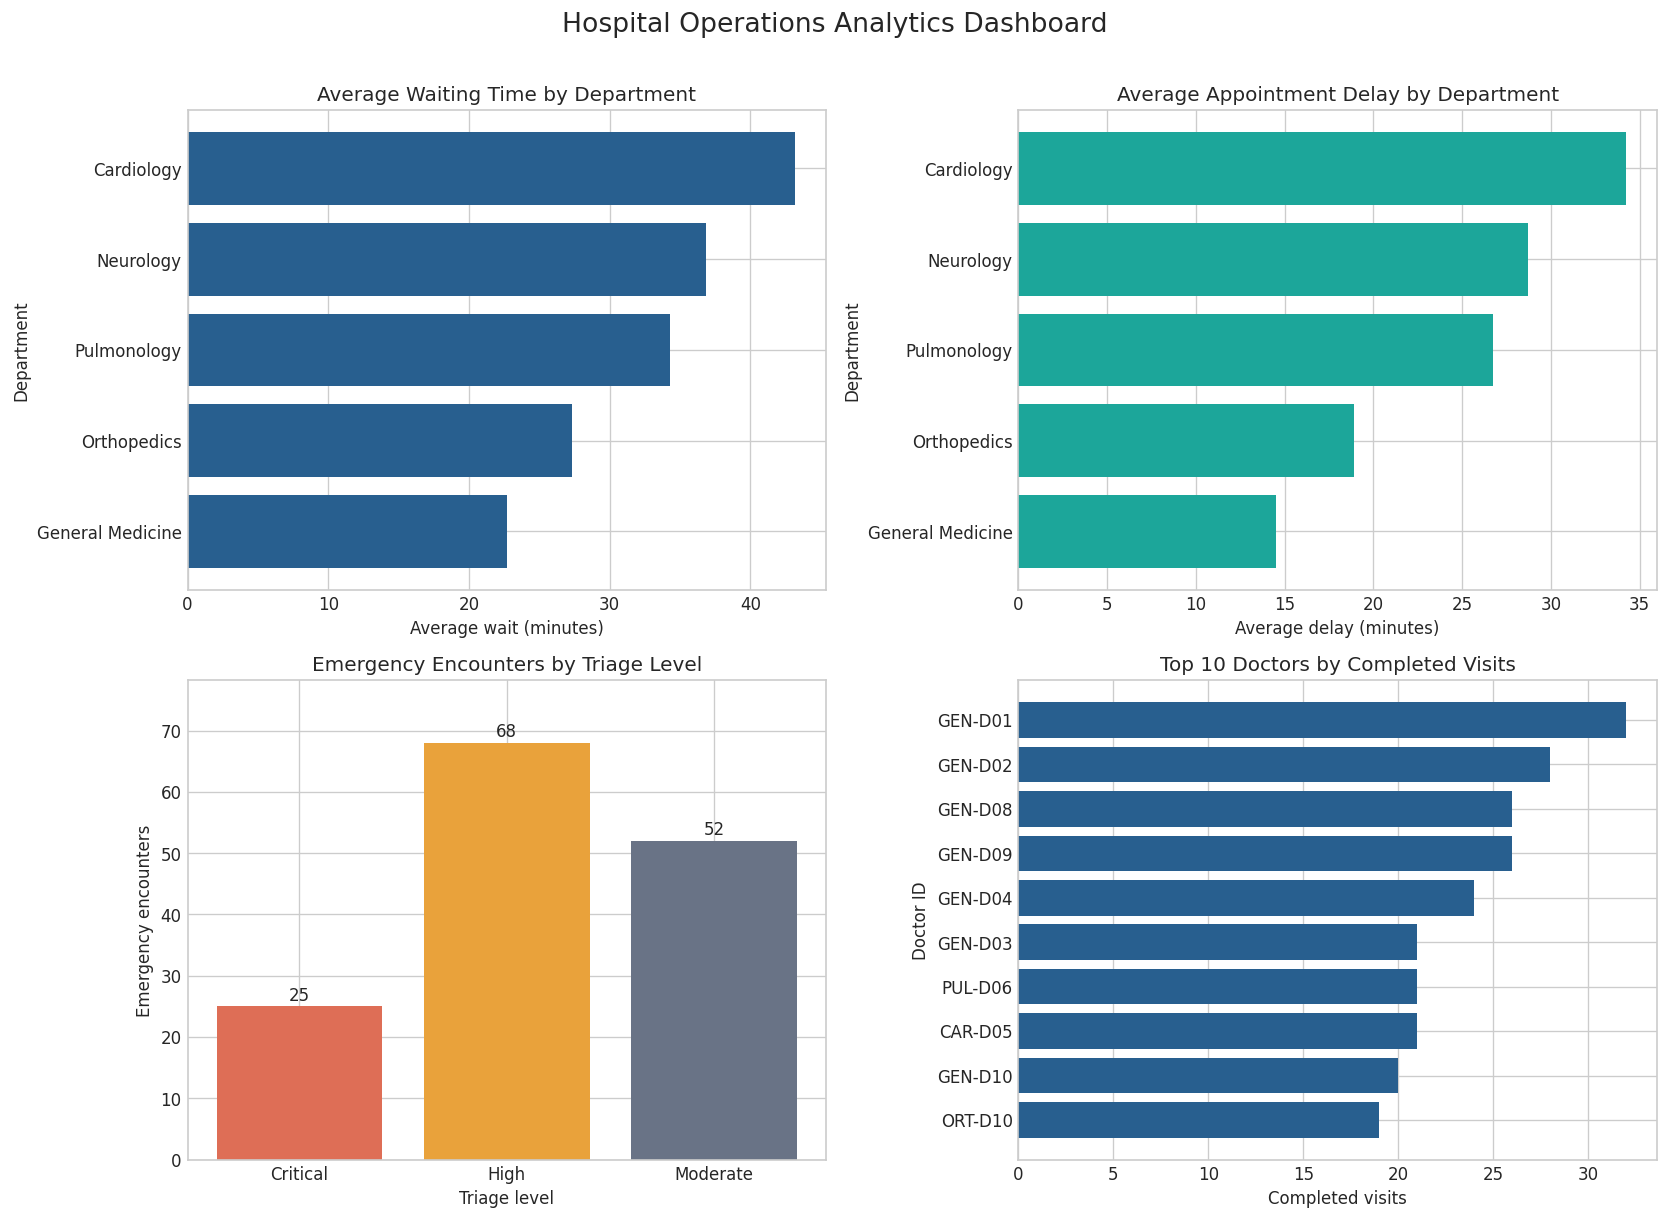

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].barh(
    wait_by_department["department"],
    wait_by_department["waiting_time_minutes"],
    color=COLORS["blue"],
)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("Average Waiting Time by Department")
axes[0, 0].set_xlabel("Average wait (minutes)")
axes[0, 0].set_ylabel("Department")

axes[0, 1].barh(
    delay_by_department["department"],
    delay_by_department["appointment_delay_minutes"],
    color=COLORS["teal"],
)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("Average Appointment Delay by Department")
axes[0, 1].set_xlabel("Average delay (minutes)")
axes[0, 1].set_ylabel("Department")

triage_colors = [COLORS["coral"], COLORS["gold"], COLORS["grey"]]
axes[1, 0].bar(
    emergency_by_triage.index,
    emergency_by_triage.values,
    color=triage_colors,
)
axes[1, 0].set_title("Emergency Encounters by Triage Level")
axes[1, 0].set_xlabel("Triage level")
axes[1, 0].set_ylabel("Emergency encounters")
axes[1, 0].set_ylim(0, max(emergency_by_triage.values) * 1.15)
for position, value in enumerate(emergency_by_triage.values):
    axes[1, 0].text(position, value + 1, str(value), ha="center")

top_doctors = doctor_workload.head(10).sort_values(
    "completed_visits", ascending=True
)
axes[1, 1].barh(
    top_doctors["doctor_id"],
    top_doctors["completed_visits"],
    color=COLORS["blue"],
)
axes[1, 1].set_title("Top 10 Doctors by Completed Visits")
axes[1, 1].set_xlabel("Completed visits")
axes[1, 1].set_ylabel("Doctor ID")

fig.suptitle("Hospital Operations Analytics Dashboard", fontsize=16, y=1.01)
fig.tight_layout()
plt.show()

## 7. Pipeline Validation

In [11]:
matched_cases = encounters[encounters["doctor_match_status"] == "Matched"]

validation_results = {
    "encounter_id_unique_after_cleaning": bool(encounters["encounter_id"].is_unique),
    "patient_id_complete": bool(encounters["patient_id"].notna().all()),
    "normal_appointments_have_doctor": bool(normal_appointments["doctor_id"].notna().all()),
    "normal_appointments_inside_doctor_shift": bool(
        normal_appointments["calculated_within_doctor_shift"].all()
    ),
    "emergencies_have_priority_queue": bool(
        emergency_review_queue["priority_queue"].notna().all()
    ),
    "emergencies_require_doctor_decision": bool(
        emergency_review_queue["doctor_decision_required"].eq("Yes").all()
    ),
    "matched_doctor_specialization_matches_department": bool(
        matched_cases["doctor_specialization"].eq(
            matched_cases["department"]
        ).all()
    ),
    "completed_wait_times_non_negative": bool(
        completed_appointments["waiting_time_minutes"].ge(0).all()
    ),
    "completed_delays_non_negative": bool(
        completed_appointments["appointment_delay_minutes"].ge(0).all()
    ),
    "risk_score_in_expected_range": bool(
        patient_analytics["risk_score"].between(0, 12).all()
    ),
}

validation_report = pd.Series(validation_results, name="passed").to_frame()
validation_report

,passed
encounter_id_unique_after_cleaning,True
patient_id_complete,True
normal_appointments_have_doctor,True
normal_appointments_inside_doctor_shift,True
emergencies_have_priority_queue,True
emergencies_require_doctor_decision,True
matched_doctor_specialization_matches_department,True
completed_wait_times_non_negative,True
completed_delays_non_negative,True
risk_score_in_expected_range,True


## 8. Store Curated Outputs

In [12]:
OUTPUT_DIR.mkdir(exist_ok=True)

encounters.to_csv(OUTPUT_DIR / "clean_hospital_encounters.csv", index=False)
patient_analytics.to_csv(OUTPUT_DIR / "hospital_patient_analytics.csv", index=False)
emergency_review_queue.to_csv(OUTPUT_DIR / "emergency_review_queue.csv", index=False)
doctor_workload.to_csv(OUTPUT_DIR / "doctor_workload_summary.csv", index=False)

print("Saved curated encounter, patient, emergency and doctor-workload outputs.")

Saved curated encounter, patient, emergency and doctor-workload outputs.


## 9. Monitoring, Security and Governance

- Monitor source freshness, duplicate IDs, failed records, unmatched emergencies, shift violations and schema changes.
- Encrypt patient data in transit and at rest and apply role-based access.
- Use coded identifiers or aggregated values on general dashboards.
- Record appointment changes, emergency escalations, data access and pipeline runs in audit logs.
- Keep source-provided triage separate from analytical risk scores.
- Require qualified clinical staff to make all diagnosis, treatment and emergency-care decisions.

## Takeaways

This implementation now follows the full proposed flow. It integrates hospital records, verifies normal appointments against doctor shifts, separates on-call emergency coverage, creates a priority review queue, identifies cases needing further doctor matching, analyses waiting time and delays, and reports doctor workload. The automated steps organise information and support staff action; they do not replace clinical judgement.